# Introdução ao Keras

## 1. Setup

In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # silencia logs do TensorFlow (antes de importar keras)
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)
print('keras', keras.__version__, '| backend:', keras.backend.backend())

keras 3.13.2 | backend: tensorflow


## 2. Dados

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(455, 30) (114, 30) (455,) (114,)


## 3. Baseline sklearn

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# o de sempre: fit / predict / score
lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)
print('LogisticRegression:', lr.score(X_test, y_test))
print('RandomForest      :', rf.score(X_test, y_test))

LogisticRegression: 0.9824561403508771
RandomForest      : 0.956140350877193


## 4. Primeiro modelo Keras — Sequential

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(30,)),               # 30 features
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid'),  # 1 saída = probabilidade da classe 1
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

## 5. compile()

In [ ]:
# versão com strings
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# mesma coisa com objetos (permite ajustar learning_rate, adicionar métricas...)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=['accuracy', keras.metrics.AUC(name='auc')],
)

## 6. fit()

In [ ]:
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9835 - loss: 0.0772 - val_accuracy: 0.9890 - val_loss: 0.0569
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9863 - loss: 0.0605 - val_accuracy: 0.9890 - val_loss: 0.0558
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9890 - loss: 0.0628 - val_accuracy: 0.9890 - val_loss: 0.0546
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9890 - loss: 0.0604 - val_accuracy: 0.9890 - val_loss: 0.0535
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9890 - loss: 0.0541 - val_accuracy: 0.9890 - val_loss: 0.0523
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9835 - loss: 0.0625 - val_accuracy: 0.9890 - val_loss: 0.0512
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9863 - loss: 0.0598 - val_accuracy: 0.9890 - val_loss: 0.0504
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9890 - loss: 0.0547 - val_accuracy: 0.9890 - v

In [ ]:
hist = pd.DataFrame(history.history)
hist.tail(3)

,accuracy,auc,loss,val_accuracy,val_auc,val_loss
27,0.989011,0.996147,0.072388,0.989011,0.998759,0.060731
28,0.986264,0.996734,0.066430,0.989011,0.999007,0.059489
29,0.980769,0.997730,0.066529,0.989011,0.999007,0.058177


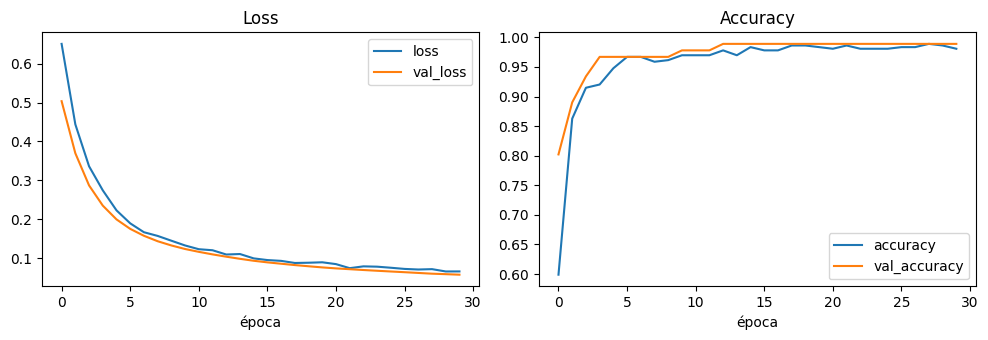

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
hist[['loss', 'val_loss']].plot(ax=ax[0], title='Loss')
hist[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
for a in ax: a.set_xlabel('época')
plt.tight_layout(); plt.show()

## 7. evaluate() e predict()

In [ ]:
resultados = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
{k: round(v, 4) for k, v in resultados.items()}

{'accuracy': 0.9561, 'auc': 0.9932, 'loss': 0.1061}

In [ ]:
proba = model.predict(X_test, verbose=0)   # probabilidades, shape (n, 1)
y_pred = (proba[:, 0] > 0.5).astype(int)   # threshold 0.5 -> classe
print(proba[:5].ravel().round(3), y_pred[:5])

[0.    1.    0.029 0.555 0.   ] [0 1 0 1 0]


              precision    recall  f1-score   support

           0       0.93      0.95      0.94        42
           1       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



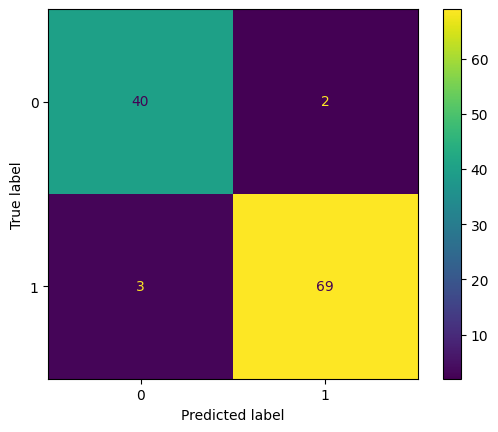

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# métricas do sklearn continuam servindo
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(); plt.show()

## 8. Rosetta Stone: sklearn ↔ Keras

In [ ]:
from sklearn.metrics import accuracy_score

# sklearn: fit / predict          |  Keras: compile / fit / predict (+ threshold)
pred_lr = lr.predict(X_test)
pred_rf = rf.predict(X_test)
pred_nn = (model.predict(X_test, verbose=0)[:, 0] > 0.5).astype(int)

pd.DataFrame({
    'modelo':   ['LogisticRegression', 'RandomForest', 'Keras MLP'],
    'treino':   ['.fit(X, y)', '.fit(X, y)', '.compile(...) + .fit(X, y, epochs=...)'],
    'predição': ['.predict(X)', '.predict(X)', '.predict(X) > 0.5'],
    'accuracy': [accuracy_score(y_test, p) for p in (pred_lr, pred_rf, pred_nn)],
}).round(4)

,modelo,treino,predição,accuracy
0,LogisticRegression,".fit(X, y)",.predict(X),0.9825
1,RandomForest,".fit(X, y)",.predict(X),0.9561
2,Keras MLP,".compile(...) + .fit(X, y, epochs=...)",.predict(X) > 0.5,0.9561


## 9. Callbacks

In [ ]:
CKPT = os.path.join(os.environ.get('CKPT_DIR', '.'), 'melhor_modelo.keras')

def novo_modelo(units=32, dropout=0.2):
    m = keras.Sequential([keras.Input(shape=(30,)),
                          layers.Dense(units, activation='relu'),
                          layers.Dropout(dropout),
                          layers.Dense(1, activation='sigmoid')])
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(CKPT, monitor='val_loss', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5),
]
model_cb = novo_modelo()
h = model_cb.fit(X_train, y_train, epochs=200, batch_size=32, validation_split=0.2,
                 callbacks=callbacks, verbose=0)

val_loss = h.history['val_loss']
melhor = int(np.argmin(val_loss)) + 1
print(f'parou na época {len(val_loss)} de 200 | melhor época = {melhor} (val_loss={min(val_loss):.4f})')

parou na época 175 de 200 | melhor época = 160 (val_loss=0.0233)


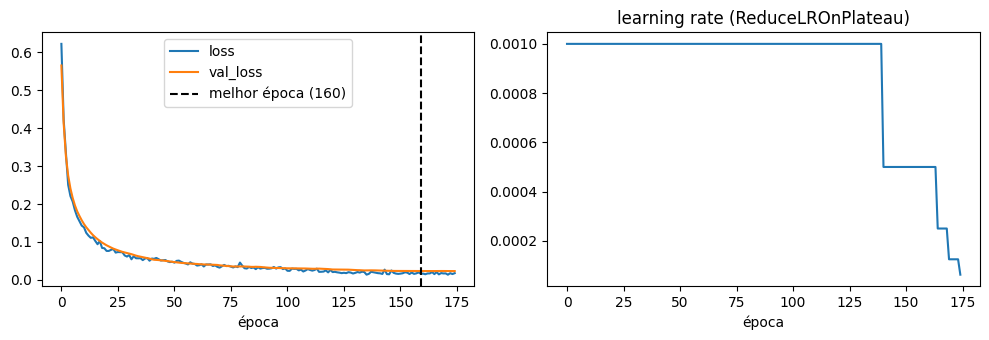

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.history['loss'], label='loss'); ax[0].plot(val_loss, label='val_loss')
ax[0].axvline(melhor - 1, color='k', ls='--', label=f'melhor época ({melhor})'); ax[0].legend(); ax[0].set_xlabel('época')
ax[1].plot(h.history['learning_rate']); ax[1].set_title('learning rate (ReduceLROnPlateau)'); ax[1].set_xlabel('época')
plt.tight_layout(); plt.show()

In [ ]:
carregado = keras.saving.load_model(CKPT)
print('modelo em memória (restore_best_weights):', model_cb.evaluate(X_test, y_test, verbose=0))
print('modelo carregado do disco              :', carregado.evaluate(X_test, y_test, verbose=0))

modelo em memória (restore_best_weights): [0.09313562512397766, 0.9561403393745422]


modelo carregado do disco              : [0.09313562512397766, 0.9561403393745422]


## 10. Explorando hiperparâmetros

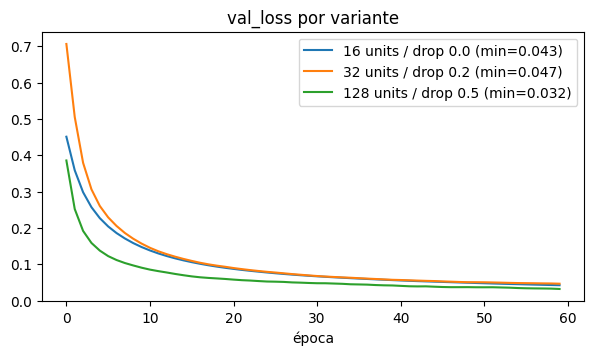

In [ ]:
variantes = {'16 units / drop 0.0': (16, 0.0), '32 units / drop 0.2': (32, 0.2), '128 units / drop 0.5': (128, 0.5)}
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

plt.figure(figsize=(7, 3.5))
for nome, (u, d) in variantes.items():
    hv = novo_modelo(u, d).fit(X_train, y_train, epochs=60, batch_size=32, validation_split=0.2,
                               callbacks=[es], verbose=0)
    plt.plot(hv.history['val_loss'], label=f'{nome} (min={min(hv.history["val_loss"]):.3f})')
plt.title('val_loss por variante'); plt.xlabel('época'); plt.legend(); plt.show()

## 11. Functional API

In [ ]:
inputs = keras.Input(shape=(30,))
x = layers.Dense(32, activation='relu')(inputs)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model_fn = keras.Model(inputs=inputs, outputs=outputs, name='mlp_functional')

model_fn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_fn.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)
print('accuracy teste:', round(model_fn.evaluate(X_test, y_test, verbose=0)[1], 4))

accuracy teste: 0.9649


In [ ]:
try:
    from IPython.display import display
    display(keras.utils.plot_model(model_fn, show_shapes=True))   # requer pydot + graphviz
except Exception as e:
    print('plot_model indisponível (', type(e).__name__, ') -> usando summary()')
    model_fn.summary()

plot_model indisponível ( ImportError ) -> usando summary()


Model: "mlp_functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,077 (12.02 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,052 (8.02 KB)

## 12. Regressão em 5 linhas

In [ ]:
from sklearn.datasets import make_regression
Xr, yr = make_regression(n_samples=2000, n_features=10, noise=10, random_state=42)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)

reg = keras.Sequential([keras.Input(shape=(10,)), layers.Dense(32, activation='relu'), layers.Dense(1)])  # saída linear
reg.compile(optimizer='adam', loss='mse', metrics=['mae'])
reg.fit(Xr_tr, yr_tr, epochs=100, batch_size=32, validation_split=0.2, verbose=0)
print('teste [mse, mae]:', np.round(reg.evaluate(Xr_te, yr_te, verbose=0), 2))

teste [mse, mae]: [531.67  19.17]


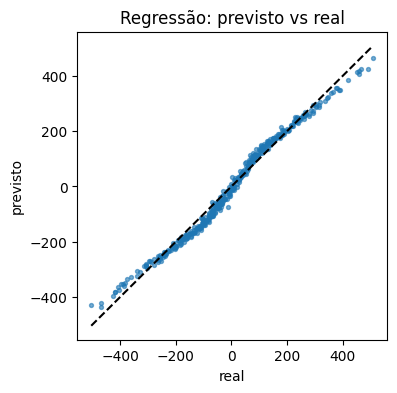

In [ ]:
yr_pred = reg.predict(Xr_te, verbose=0)[:, 0]
plt.figure(figsize=(4, 4)); plt.scatter(yr_te, yr_pred, s=8, alpha=0.6)
plt.plot([yr_te.min(), yr_te.max()], [yr_te.min(), yr_te.max()], 'k--')
plt.xlabel('real'); plt.ylabel('previsto'); plt.title('Regressão: previsto vs real'); plt.show()

## 13. Próximos passos
- `layers.Conv2D` + `MaxPooling2D` + `Flatten` para imagens
- `layers.LSTM` / `layers.GRU` para sequências e séries temporais
- Exemplos prontos: https://keras.io/examples/